# Deep self-learning enables fast, high-fidelity isotropic resolution restoration for volumetric fluorescence microscopy.
Ning, K., Lu, B., Wang, X. et al. Light Sci Appl 12, 204 (2023)
 https://doi.org/10.1038/s41377-023-01230-2

This notebook has been designed to help users work with Self-net, a deep learning model developed in Python and designed for isotropy reconstruction using a single stack.

Please, if you wish to use the original code from the paper refer to the following link:
https://zenodo.org/records/7882519

Inside the *code.rar* folder, you will find a *read.me* file containing all the instructions on how to generate the data, and how to carry out the training and testing.

![![Screenshot From 2026-04-20 11-21-38.png](<attachment:Screenshot From 2026-04-20 11-21-38.png>)](<attachment:Screenshot From 2026-04-20 11-21-38.png>)
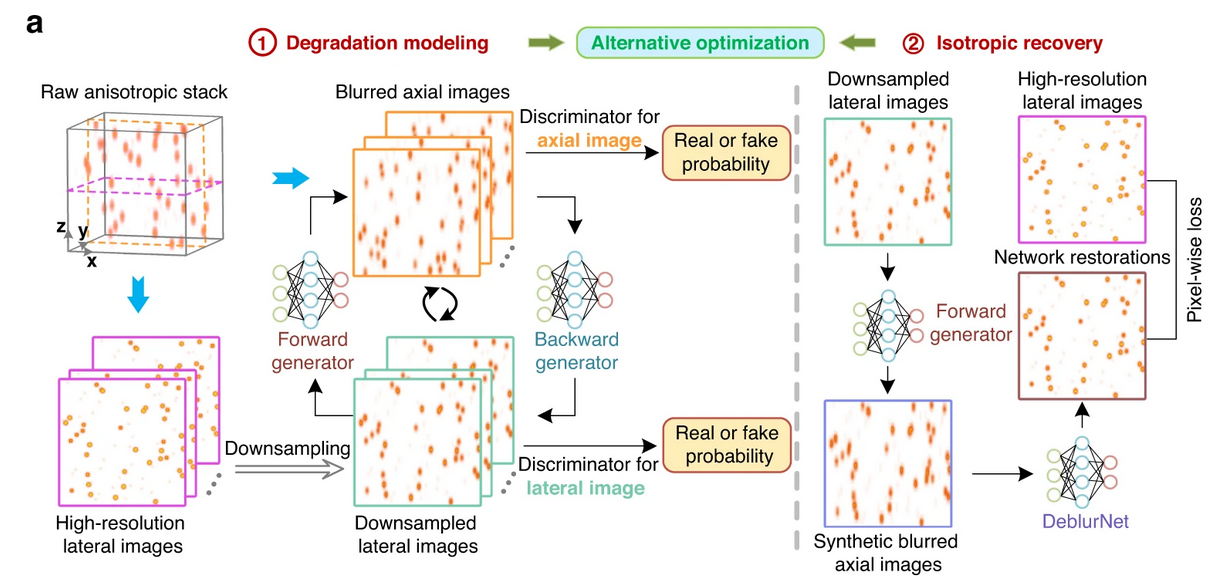

## 1. Data Generation

This first notebook is dedicated to generating the dataset.

As described in the paper, in the first stage unpaired lateral and axial slices obtained from the same image stack are fed into the CycleGAN model to learn the anisotropic degradation process.

To reduce the resolution gap between the lateral and axial views, we downsample the lateral images. This process helps the networks to focus on learning the anisotropic PSF.

The following steps apply this downsampling process which corresponds to the MATLAB code in the original code.

### 1.1 Import packages 

In [99]:
import os
import numpy as np
import tifffile
from skimage.transform import resize

### 1.2 Utils

In this section you are defining some useful methods to generate the dataset.

#### 1.2.1 Read .tiff stack

Read a single stack from the specified path

In [100]:
def tiffread (path):
    """Read a .tiff stack and return a (Y, X, Z) float32 array."""
    stack = tifffile.imread(path)
    if stack.ndim == 2:
        stack = stack[np.newaxis, ...]
    return stack.astype(np.float32)

#### 1.2.2 Write .tiff stack

Write a single stack inside the specified path

In [101]:
def tiffwrite (path, stack, bits=16):
    """Write a (Y, X, Z) array as a .tiff file."""
    if bits == 16:
        stack = stack.astype(np.float32)
    else:
        stack = stack.astype(np.uint16)
    tifffile.imwrite(path, stack, compression='lzw', photometric='minisblack')

#### 1.2.3 Image resize and reslice

The images in Z-axes are interpolate to have same pixel size of the high resolution lateral images. To help the network to learn the PSF, lateral images are downsampled in the vertical direction at a certain scale (specifically, the axial step size divided by the pixel size in the lateral plane) and then interpolated to the original size.

The following functions apply those steps.

In [102]:
def imresize(image, output_shape):
    """Bicubic resize preserving uint16 range."""
    resized = resize(
        image,
        output_shape,
        order=3,
        mode='reflect',
        anti_aliasing=True,
        preserve_range=True
    )
    return np.clip(resized, 0, 65535).astype(np.float32)

In [103]:
def reslice(stack, orientation, x_res, z_res):
    """
    Reslice a 3D stack along 'xz' or 'yz'.
    

    Parameters:
    -----------
    stack       : float16, (Y, X, Z) array
    orientation : str, 'xz' or 'yz'
    x_res       : float, lateral pixel size
    z_res       : float, axial pixel size
    """

    scale = z_res / x_res
    z,y,x = stack.shape
    new_z = int(np.round(z * scale))

    if orientation == 'xz':
        # One output image per Y row: extract (X, Z) plane at each Y, rescale Z-axis
        reslice_img = np.zeros((new_z, y, x), dtype=np.float32)
        for k in range(y):
            im_k = stack [:, k, :]
            im_k = imresize(im_k, (new_z, x))
            reslice_img[:, k, :] = im_k
        
    
    elif orientation == 'yz':
        # One output image per X column: extract (Y, Z) plane at each X, rescale Z-axis
        reslice_img = np.zeros((new_z, y, x), dtype=np.float32)
        for k in range(x):
            im_k = stack [:, :, k]
            im_k = imresize(im_k, (new_z, y))
            reslice_img[:, :, k] = im_k
    

    else:
        raise ValueError("Unknown orientation: {}. Use 'xz' or 'yz'.".format(orientation))
    
    return reslice_img

### 1.3 Folders creation and downsampling

This section is dedicated to create and save the new images generated by the previous utils functions. The code will create a general folder *dataset* that will have the following structure:

- `raw_data`:
    - `xy`: folder containing the HR lateral images
    - `xy_lr`: folder containing the downsampled lateral images
    - `xz`: folder containing all the XZ-plane images resized
    - `yz`: folder containing all the YZ-plane images resized
    
- `train_data`:
    - `train_data.npz`

The images are saved in numerical order from 1 up to depth of the Z-stack in *.tiff* files.

**raw_data** folder example:

- `raw_data`:
    - `xy`:
        - `1.tiff`
        - `2.tiff`
        - `3.tiff`
        - `...`
    - `xy_lr`:
        - `1.tiff`
        - `2.tiff`
        - `3.tiff`
        - `...`
    - `xz`:
        - `1.tiff`
        - `2.tiff`
        - `3.tiff`
        - `...`
    - `yz`:
        - `1.tiff`
        - `2.tiff`
        - `3.tiff`
        - `...`        

#### 1.3.1 Paths definition and folders creation

In [104]:
# path to the z-stack
z_stack_path = "/home/gerardo/Desktop/master_thesis_isotropy_resolution/selfnet_complete_with_notebook/"    # "path/to/your/z-stack/"
data_name = "first_channel_mahe_f16.tif" #z-stack filename

#dataset folder is created in the current working directory (Modify this path if you want to save the dataset in a different location)
dataset_path = os.path.join("..","dataset")
if not os.path.exists(dataset_path):
    os.makedirs(dataset_path, exist_ok=True)

#raw_data and train_data folders are created inside dataset
raw_data_path = os.path.join(dataset_path,"raw_data")
train_data_path = os.path.join(dataset_path,"train_data")


xy_path = os.path.join(raw_data_path, "xy")
xy_lr_path = os.path.join(raw_data_path, "xy_lr")
xz_path = os.path.join(raw_data_path, "xz")
yz_path = os.path.join(raw_data_path, "yz")

for folder in (xy_path, xy_lr_path, xz_path, yz_path):
    os.makedirs(folder, exist_ok=True)

#### 1.3.2 Reading the .tiff file

In [105]:
print("Reading z-stack...")
raw_data = tiffread(os.path.join(z_stack_path, data_name))
z,y,x = raw_data.shape
print("Stack shape: (Z, Y, X) = ({}, {}, {})".format(z, y, x))

Reading z-stack...
Stack shape: (Z, Y, X) = (439, 850, 850)


#### 1.3.3 Images generation

In [106]:
#Specitfy here the lateral and axial resolutions of the z-stack
x_res = 0.27   #lateral pixel size
z_res = 0.5    #axial step size

##### XY and XY_LR slices

In [107]:
# -- XY and XY_LR slices--
print("\nSaving XY and XY_LR slices...")
for index in range(z):
    image = raw_data[index, :, :]
    
    tifffile.imwrite(os.path.join(xy_path, "%d.tif" % (index + 1)), image.astype(np.float32))

    # downsample
    downsample_img = imresize(image, (int(round(y*x_res)), x))
    downsample_img = imresize(downsample_img, (y, x))
    tifffile.imwrite(os.path.join(xy_lr_path, "%d.tif" % (index +1)), downsample_img.astype(np.float32))
    if (index + 1) % 10 == 0 or index == z - 1:
        print("Saved {}/{} XY slices".format(index + 1, z))


Saving XY and XY_LR slices...
Saved 10/439 XY slices
Saved 20/439 XY slices
Saved 30/439 XY slices
Saved 40/439 XY slices
Saved 50/439 XY slices
Saved 60/439 XY slices
Saved 70/439 XY slices
Saved 80/439 XY slices
Saved 90/439 XY slices
Saved 100/439 XY slices
Saved 110/439 XY slices
Saved 120/439 XY slices
Saved 130/439 XY slices
Saved 140/439 XY slices
Saved 150/439 XY slices
Saved 160/439 XY slices
Saved 170/439 XY slices
Saved 180/439 XY slices
Saved 190/439 XY slices
Saved 200/439 XY slices
Saved 210/439 XY slices
Saved 220/439 XY slices
Saved 230/439 XY slices
Saved 240/439 XY slices
Saved 250/439 XY slices
Saved 260/439 XY slices
Saved 270/439 XY slices
Saved 280/439 XY slices
Saved 290/439 XY slices
Saved 300/439 XY slices
Saved 310/439 XY slices
Saved 320/439 XY slices
Saved 330/439 XY slices
Saved 340/439 XY slices
Saved 350/439 XY slices
Saved 360/439 XY slices
Saved 370/439 XY slices
Saved 380/439 XY slices
Saved 390/439 XY slices
Saved 400/439 XY slices
Saved 410/439 XY s

##### XZ slices

In [108]:
# -- XZ slices--
print("\nReslicing XZ slices...")
xz_raw = reslice(raw_data, 'xz', x_res, z_res)

for index in range(y):
    image = xz_raw[:, index, :]
    tifffile.imwrite(os.path.join(xz_path, "%d.tif" % (index + 1)), image.astype(np.float32))
    if (index + 1) % 10 == 0 or index == y - 1:
        print("Saved {}/{} XZ slices".format(index + 1, y))


Reslicing XZ slices...
Saved 10/850 XZ slices
Saved 20/850 XZ slices
Saved 30/850 XZ slices
Saved 40/850 XZ slices
Saved 50/850 XZ slices
Saved 60/850 XZ slices
Saved 70/850 XZ slices
Saved 80/850 XZ slices
Saved 90/850 XZ slices
Saved 100/850 XZ slices
Saved 110/850 XZ slices
Saved 120/850 XZ slices
Saved 130/850 XZ slices
Saved 140/850 XZ slices
Saved 150/850 XZ slices
Saved 160/850 XZ slices
Saved 170/850 XZ slices
Saved 180/850 XZ slices
Saved 190/850 XZ slices
Saved 200/850 XZ slices
Saved 210/850 XZ slices
Saved 220/850 XZ slices
Saved 230/850 XZ slices
Saved 240/850 XZ slices
Saved 250/850 XZ slices
Saved 260/850 XZ slices
Saved 270/850 XZ slices
Saved 280/850 XZ slices
Saved 290/850 XZ slices
Saved 300/850 XZ slices
Saved 310/850 XZ slices
Saved 320/850 XZ slices
Saved 330/850 XZ slices
Saved 340/850 XZ slices
Saved 350/850 XZ slices
Saved 360/850 XZ slices
Saved 370/850 XZ slices
Saved 380/850 XZ slices
Saved 390/850 XZ slices
Saved 400/850 XZ slices
Saved 410/850 XZ slices
S

##### YZ slices

In [109]:
# -- YZ slices--
print("\nReslicing YZ slices...")
yz_raw = reslice(raw_data, 'yz', x_res, z_res)

for index in range(x):
    image = yz_raw[:, :, index]
    tifffile.imwrite(os.path.join(yz_path, "%d.tif" % (index + 1)), image.astype(np.float32))
    if (index + 1) % 10 == 0 or index == x - 1:
        print("Saved {}/{} YZ slices".format(index + 1, x))

print("\nAll slices saved successfully.")


Reslicing YZ slices...
Saved 10/850 YZ slices
Saved 20/850 YZ slices
Saved 30/850 YZ slices
Saved 40/850 YZ slices
Saved 50/850 YZ slices
Saved 60/850 YZ slices
Saved 70/850 YZ slices
Saved 80/850 YZ slices
Saved 90/850 YZ slices
Saved 100/850 YZ slices
Saved 110/850 YZ slices
Saved 120/850 YZ slices
Saved 130/850 YZ slices
Saved 140/850 YZ slices
Saved 150/850 YZ slices
Saved 160/850 YZ slices
Saved 170/850 YZ slices
Saved 180/850 YZ slices
Saved 190/850 YZ slices
Saved 200/850 YZ slices
Saved 210/850 YZ slices
Saved 220/850 YZ slices
Saved 230/850 YZ slices
Saved 240/850 YZ slices
Saved 250/850 YZ slices
Saved 260/850 YZ slices
Saved 270/850 YZ slices
Saved 280/850 YZ slices
Saved 290/850 YZ slices
Saved 300/850 YZ slices
Saved 310/850 YZ slices
Saved 320/850 YZ slices
Saved 330/850 YZ slices
Saved 340/850 YZ slices
Saved 350/850 YZ slices
Saved 360/850 YZ slices
Saved 370/850 YZ slices
Saved 380/850 YZ slices
Saved 390/850 YZ slices
Saved 400/850 YZ slices
Saved 410/850 YZ slices
S

### 1.4 Training dataset generation

The training dataset is generated starting from the images inside *raw_data* folder. The images are divided per patches and saved in a numpy array (*.npz* file). 

To ensure the patches are selected appropriately, a threshold has been introduced. Specifically, the training dataset will consist of all patches that satisfy the following condition:

$$\max(I_{*}) \geq T_s \implies I_{*} \in \mathcal{D}$$

Where:
- $I_{*}$ is the * section image (`crop_*`)
- $T_s$ is the signal intensity threshold (`signal_intensity_threshold`)
- $\mathcal{D}$ is the dataset of selected images
- $\max(\cdot)$ is the maximum value function

In addition to the threshold, you can specify the size of each patch, the stride, and the interval used to sample each plane.

**Note**: This step is crucial! A dataset that is too large could cause an *out-of-memory* error during training

In [110]:
xy = []
xy_lr = []
xz = []

# -- Parameters for patch extraction --
stride = 64
patch_size = 128

signal_intensity_threshold = 1    #Minimum intensity for a valid patch

xy_interval=4     #Interval for extracting XY patches (every n-th slice)
xz_interval=5     #Interval for extracting XZ patches (every n-th slice)

##### XY and XY_LR

In [111]:
print("\nExtracting patches...")
for i in range(0, len(os.listdir(xy_path)), xy_interval):

    xy_img = tifffile.imread(xy_path + "/" + str(i + 1) + '.tif')
    xy_lr_img = tifffile.imread(xy_lr_path + "/" + str(i + 1) + '.tif')
    print(i + 1)

    for m in range(0, xy_img.shape[0] - patch_size + 1, stride):
        for n in range(0, xy_img.shape[1] - patch_size + 1, stride):
            crop_xy = xy_img[m:m + patch_size, n:n + patch_size]
            crop_xy_lr = xy_lr_img[m:m + patch_size, n:n + patch_size]

            if np.max(crop_xy >= signal_intensity_threshold):
                xy.append(crop_xy)
                xy_lr.append(crop_xy_lr)


Extracting patches...
1
5
9
13
17
21
25
29
33
37
41
45
49
53
57
61
65
69
73
77
81
85
89
93
97
101
105
109
113
117
121
125
129
133
137
141
145
149
153
157
161
165
169
173
177
181
185
189
193
197
201
205
209
213
217
221
225
229
233
237
241
245
249
253
257
261
265
269
273
277
281
285
289
293
297
301
305
309
313
317
321
325
329
333
337
341
345
349
353
357
361
365
369
373
377
381
385
389
393
397
401
405
409
413
417
421
425
429
433
437


##### XZ

In [112]:
for i in range(0, len(os.listdir(xz_path)), xz_interval):
    xz_img = tifffile.imread(xz_path + "/" + str(i + 1) + '.tif')
    print(i + 1)

    for m in range(0, xz_img.shape[0] - patch_size + 1, stride):
        for n in range(0, xz_img.shape[1] - patch_size + 1, stride):
            crop_xz = xz_img[m:m + patch_size, n:n + patch_size]

            if np.max(crop_xz >= signal_intensity_threshold):
                xz.append(crop_xz)

1
6
11
16
21
26
31
36
41
46
51
56
61
66
71
76
81
86
91
96
101
106
111
116
121
126
131
136
141
146
151
156
161
166
171
176
181
186
191
196
201
206
211
216
221
226
231
236
241
246
251
256
261
266
271
276
281
286
291
296
301
306
311
316
321
326
331
336
341
346
351
356
361
366
371
376
381
386
391
396
401
406
411
416
421
426
431
436
441
446
451
456
461
466
471
476
481
486
491
496
501
506
511
516
521
526
531
536
541
546
551
556
561
566
571
576
581
586
591
596
601
606
611
616
621
626
631
636
641
646
651
656
661
666
671
676
681
686
691
696
701
706
711
716
721
726
731
736
741
746
751
756
761
766
771
776
781
786
791
796
801
806
811
816
821
826
831
836
841
846


##### Save to *.npz*

In [114]:
xy = np.array(xy, dtype=np.float32)
xy_lr = np.array(xy_lr, dtype=np.float32)
xz = np.array(xz, dtype=np.float32)
print(xy.shape, xy_lr.shape, xz.shape)

os.makedirs(train_data_path, exist_ok=True)
np.savez(train_data_path + '/train_data.npz', xy=xy, xy_lr=xy_lr, xz=xz)

(15840, 128, 128) (15840, 128, 128) (22440, 128, 128)
